# 03. Líneas Base y Comparación de Modelos Candidatos en MLflow

**Proyecto:** PSet #3 — Experimentación y Selección del Modelo con MLflow  
**Experimento MLflow:** `nowcasting-f104-sri` (`http://localhost:5000`)  
**Objetivo:** Justificar el esquema de validación cruzada temporal, definir las métricas técnica y de negocio, entrenar y registrar las **2 líneas base** y **5 familias de modelos candidatos** con hiperparámetros por defecto, además de evaluar formalmente el planteamiento mediante prompting de un LLM.

In [1]:
import logging
import os
import sys
import time
import warnings
from pathlib import Path

import lightgbm
from lightgbm import LGBMRegressor
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from dotenv import load_dotenv
from IPython.display import display
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GroupKFold, KFold, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

load_dotenv(ROOT / ".env", override=False)
logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

from src.datos import (
    dividir_train_test,
    obtener_metadatos_snapshot,
    preparar_universo_nowcasting,
)
from src.pipeline import (
    COLUMNAS_MODELO,
    OBJETIVO,
    HeuristicaBCE,
    agregar_features,
    calcular_costo_negocio_musd,
    calcular_metricas,
    calcular_wape_pct,
    construir_preparacion,
)

FIG_DIR = ROOT / "docs" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

SEMILLA = 42
TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://localhost:5000")
EXPERIMENTO = os.environ.get("MLFLOW_EXPERIMENT_NAME", "nowcasting-f104-sri")

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENTO)
client = MlflowClient()
exp = client.get_experiment_by_name(EXPERIMENTO)

# Limpiar corridas previas del experimento para que 03 -> 04 -> 05 produzca evidencia limpia sin duplicados
prev_runs = client.search_runs(experiment_ids=[exp.experiment_id], max_results=5000)
for r in prev_runs:
    client.delete_run(r.info.run_id)
print(f"MLflow conectado: {mlflow.get_tracking_uri()} | Experimento: {EXPERIMENTO} (id={exp.experiment_id})")

meta = obtener_metadatos_snapshot()
print("Metadatos trazabilidad:", meta)

MLflow conectado: http://localhost:5000 | Experimento: nowcasting-f104-sri (id=1)
Metadatos trazabilidad: {'tabla_origen': 'PSET2_DB.ANALYTICS.OBT_NOWCASTING_VENTAS + PSET2_DB.ANALYTICS.PRECIOS_RAMA_CNT46', 'fecha_corte_snapshot': '2026-06-01', 'huella_datos': 'e4cd092d7514', 'git_commit': 'dda7927'}


## 1. División única y justificación del esquema de validación cruzada

1. **Partición única Train / Hold-out Test:**
   - **Entrenamiento (`2016-01-01` a `2024-12-01`):** 4,907 observaciones (108 meses × 46 ramas menos 61 cortes tempranos ausentes en rama `020`), después de reservar los primeros 12 meses de 2015 como *warmup* causal para disponer de `lag_12` completo.
   - **Prueba *hold-out* (`2025-01-01` a `2026-06-01`):** 828 observaciones (últimos 18 meses completos), intocable hasta `05_seleccion.ipynb`.
2. **Validación cruzada temporal alineada por mes (`TimeSeriesSplit(n_splits=5)` sobre meses únicos):**
   - Si se aplicara `TimeSeriesSplit` directamente por índice de fila, un pliegue podría cortar un mismo mes fiscal a mitad de sus 46 ramas (filtrando información contemporánea del mismo mes entre ramas). Por ello construimos 5 pliegues estrictamente cronológicos por `FECHA_MES` (cada pliegue de validación evalúa un bloque futuro de 18 meses, reflejando exactamente el horizonte del *hold-out*).
   - Se compara empíricamente contra `KFold(shuffle=True)` (que subestima el error al mezclar futuro y pasado) y `GroupKFold` por rama (que evalúa ramas desconocidas, escenario irreal porque las 46 ramas CIIU son fijas en el Sistema de Cuentas Nacionales).

In [2]:
universo = preparar_universo_nowcasting()
datos = agregar_features(universo)
train_df, test_df = dividir_train_test(datos)

X_ent = train_df[COLUMNAS_MODELO].copy()
y_ent = train_df[OBJETIVO].astype(float).copy()
X_prueba = test_df[COLUMNAS_MODELO].copy()
y_prueba = test_df[OBJETIVO].astype(float).copy()

meses_unicos = np.sort(train_df["FECHA_MES"].unique())
tscv_meses = TimeSeriesSplit(n_splits=5)
cv_temporal = []
print("Estructura de los 5 pliegues temporales alineados por FECHA_MES:")
for idx_f, (m_tr, m_val) in enumerate(tscv_meses.split(meses_unicos), start=1):
    fechas_tr = meses_unicos[m_tr]
    fechas_val = meses_unicos[m_val]
    tr_idx = np.where(train_df["FECHA_MES"].isin(fechas_tr))[0]
    val_idx = np.where(train_df["FECHA_MES"].isin(fechas_val))[0]
    cv_temporal.append((tr_idx, val_idx))
    print(
        f"  Pliegue {idx_f}: train {pd.Timestamp(fechas_tr[0]).strftime('%Y-%m')}..{pd.Timestamp(fechas_tr[-1]).strftime('%Y-%m')} "
        f"({len(tr_idx)} filas) -> val {pd.Timestamp(fechas_val[0]).strftime('%Y-%m')}..{pd.Timestamp(fechas_val[-1]).strftime('%Y-%m')} ({len(val_idx)} filas)"
    )

# Comparación metodológica de esquemas de CV usando Ridge(random_state=42)
def cv_mae_resumen(splits, grupos=None):
    maes = []
    for tr_i, val_i in splits:
        pipe = Pipeline([("preparar", construir_preparacion()), ("modelo", Ridge(random_state=SEMILLA))])
        pipe.fit(X_ent.iloc[tr_i], y_ent.iloc[tr_i])
        pred = np.clip(pipe.predict(X_ent.iloc[val_i]), 0.0, None)
        maes.append(calcular_metricas(y_ent.iloc[val_i], pred)["mae"])
    return float(np.mean(maes)), float(np.std(maes))

m_ts, s_ts = cv_mae_resumen(cv_temporal)
m_kf, s_kf = cv_mae_resumen(list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X_ent)))
m_gk, s_gk = cv_mae_resumen(list(GroupKFold(n_splits=5).split(X_ent, y_ent, groups=train_df["CODIGO_INDUSTRIA"])))
display(pd.DataFrame([
    {"esquema": "TimeSeriesSplit mensual (elegido)", "mae_promedio": round(m_ts, 3), "mae_std": round(s_ts, 3), "validez": "Respeta causalidad temporal sin fuga intramensual"},
    {"esquema": "KFold aleatorio (shuffle=True)", "mae_promedio": round(m_kf, 3), "mae_std": round(s_kf, 3), "validez": "Fuga temporal (entrena con futuro para predecir pasado)"},
    {"esquema": "GroupKFold por rama CIIU", "mae_promedio": round(m_gk, 3), "mae_std": round(s_gk, 3), "validez": "Evalúa ramas nunca vistas (las 46 ramas son fijas)"},
]))

Estructura de los 5 pliegues temporales alineados por FECHA_MES:
  Pliegue 1: train 2016-01..2017-06 (822 filas) -> val 2017-07..2018-12 (822 filas)
  Pliegue 2: train 2016-01..2018-12 (1644 filas) -> val 2019-01..2020-06 (810 filas)
  Pliegue 3: train 2016-01..2020-06 (2454 filas) -> val 2020-07..2021-12 (810 filas)
  Pliegue 4: train 2016-01..2021-12 (3264 filas) -> val 2022-01..2023-06 (815 filas)
  Pliegue 5: train 2016-01..2023-06 (4079 filas) -> val 2023-07..2024-12 (828 filas)


,esquema,mae_promedio,mae_std,validez
0,TimeSeriesSplit mensual (elegido),16.632,1.926,Respeta causalidad temporal sin fuga intramensual
1,KFold aleatorio (shuffle=True),14.075,0.272,Fuga temporal (entrena con futuro para predeci...
2,GroupKFold por rama CIIU,38.336,38.308,Evalúa ramas nunca vistas (las 46 ramas son fi...


## 2. Métrica técnica y métrica de negocio

- **Métrica técnica principal:** `MAE` (Error Absoluto Medio en **millones de USD reales**). Al tener las 46 ramas colas pesadas (`skew = 6.72`), el MAE mide directamente el desvío promedio en dólares reales sin ser dominado cuadráticamente por una sola rama petrolera o comercial. Se complementa con `RMSE`, `R²` y `WAPE (%)`.
- **Métricas de negocio (IMAEC Flash del BCE):**
  1. `WAPE (%)` macroeconómico: $\frac{\sum |y_i - \hat{y}_i|}{\sum |y_i|} \times 100$, que pondera naturalmente cada error por el peso real de la rama en el agregado nacional de ventas.
  2. `costo_negocio_musd`: función de pérdida asimétrica en M USD por rama-mes que penaliza **1.5×** la sobreestimación ($\hat{y} > y$: señal de falso optimismo que retrasa alertas de contracción económica) frente a **1.0×** la subestimación ($\hat{y} \le y$: sesgo conservador).

In [3]:
resultados = []
X_ejemplo = X_ent.head(5).copy()


def _limpiar_params(params: dict) -> dict:
    salida = {}
    for k, v in params.items():
        val = str(v)
        salida[f"hp_{k}"] = val[:240]
    return salida


def evaluar_y_registrar(
    nombre_run: str,
    modelo,
    fase: str,
    familia: str,
    usar_preparacion: bool = True,
) -> dict:
    fold_metrics = []
    for f_idx, (tr_i, val_i) in enumerate(cv_temporal, start=1):
        pasos = [("preparar", construir_preparacion()), ("modelo", clone(modelo))] if usar_preparacion else [("modelo", clone(modelo))]
        pipe_fold = Pipeline(pasos)
        pipe_fold.fit(X_ent.iloc[tr_i], y_ent.iloc[tr_i])
        pred_val = np.clip(pipe_fold.predict(X_ent.iloc[val_i]), 0.0, None)
        met = calcular_metricas(y_ent.iloc[val_i], pred_val)
        met["fold"] = f_idx
        fold_metrics.append(met)

    df_f = pd.DataFrame(fold_metrics)
    pasos_full = [("preparar", construir_preparacion()), ("modelo", clone(modelo))] if usar_preparacion else [("modelo", clone(modelo))]
    pipe_full = Pipeline(pasos_full)
    t0 = time.perf_counter()
    pipe_full.fit(X_ent, y_ent)
    segundos = time.perf_counter() - t0

    pred_ent = np.clip(pipe_full.predict(X_ent), 0.0, None)
    met_ent = calcular_metricas(y_ent, pred_ent)

    mae_cv = float(df_f["mae"].mean())
    std_cv = float(df_f["mae"].std(ddof=0))
    brecha = mae_cv - met_ent["mae"]

    with mlflow.start_run(run_name=nombre_run) as run:
        params_log = _limpiar_params(modelo.get_params())
        params_log.update({
            "semilla": SEMILLA,
            "tabla_origen": meta["tabla_origen"],
            "fecha_corte_snapshot": meta["fecha_corte_snapshot"],
            "huella_datos": meta["huella_datos"],
            "filas_entrenamiento": len(X_ent),
            "esquema_cv": "TimeSeriesSplit_mensual_5_pliegues",
            "objetivo": OBJETIVO,
        })
        mlflow.log_params(params_log)

        metrics_log = {
            "mae_entrenamiento": met_ent["mae"],
            "rmse_entrenamiento": met_ent["rmse"],
            "wape_entrenamiento_pct": met_ent["wape_pct"],
            "mae_cv_promedio": mae_cv,
            "mae_cv_std": std_cv,
            "rmse_cv_promedio": float(df_f["rmse"].mean()),
            "r2_cv_promedio": float(df_f["r2"].mean()),
            "wape_cv_pct": float(df_f["wape_pct"].mean()),
            "costo_negocio_cv_musd": float(df_f["costo_negocio_musd"].mean()),
            "brecha_cv_ent": brecha,
            "segundos_entrenamiento": float(segundos),
        }
        for _, row_f in df_f.iterrows():
            metrics_log[f"mae_fold_{int(row_f['fold'])}"] = float(row_f["mae"])
        mlflow.log_metrics(metrics_log)

        mlflow.set_tags({
            "fase": fase,
            "familia": familia,
            "git_commit": meta["git_commit"],
            "modelo_clase": type(modelo).__name__,
        })

        sig = infer_signature(X_ejemplo, np.clip(pipe_full.predict(X_ejemplo), 0.0, None))
        mlflow.sklearn.log_model(
            pipe_full,
            artifact_path="modelo",
            signature=sig,
            input_example=X_ejemplo,
        )
        run_id = run.info.run_id

    fila = {
        "nombre": nombre_run,
        "fase": fase,
        "familia": familia,
        "run_id": run_id,
        "mae_entrenamiento": round(met_ent["mae"], 4),
        "mae_cv_promedio": round(mae_cv, 4),
        "mae_cv_std": round(std_cv, 4),
        "brecha_cv_ent": round(brecha, 4),
        "rmse_cv_promedio": round(float(df_f["rmse"].mean()), 4),
        "r2_cv_promedio": round(float(df_f["r2"].mean()), 4),
        "wape_cv_pct": round(float(df_f["wape_pct"].mean()), 3),
        "costo_negocio_cv_musd": round(float(df_f["costo_negocio_musd"].mean()), 4),
        "segundos_entrenamiento": round(segundos, 3),
    }
    resultados.append(fila)
    print(
        f"[{fase:9s}] {nombre_run:30s} | MAE ent={met_ent['mae']:7.2f} | "
        f"MAE CV={mae_cv:7.2f} ± {std_cv:5.2f} | brecha={brecha:+7.2f} | WAPE={df_f['wape_pct'].mean():5.2f}% | {segundos:.2f}s"
    )
    return fila

## 3. Líneas Base (Ingenua y Regla de Negocio del PSet #1)

1. **`baseline_dummy_mediana`:** `DummyRegressor(strategy="median")` — predice la mediana histórica de entrenamiento sin usar ninguna variable explicativa.
2. **`baseline_heuristica_bce`:** `HeuristicaBCE()` — regla operativa propuesta en el PSet #1 que proyecta el definitivo del mes $t$ dividiendo el corte temprano entre su cobertura histórica media de los últimos 12 meses (`proyeccion_cobertura_12m`).

In [4]:
evaluar_y_registrar("baseline_dummy_mediana", DummyRegressor(strategy="median"), fase="baseline", familia="baseline_ingenua", usar_preparacion=True)
evaluar_y_registrar("baseline_heuristica_bce", HeuristicaBCE(columna="proyeccion_cobertura_12m"), fase="baseline", familia="baseline_negocio", usar_preparacion=False)

[baseline ] baseline_dummy_mediana         | MAE ent= 274.13 | MAE CV= 281.68 ± 26.09 | brecha=  +7.56 | WAPE=76.97% | 0.01s


[baseline ] baseline_heuristica_bce        | MAE ent=  13.93 | MAE CV=  13.80 ±  1.48 | brecha=  -0.13 | WAPE= 3.77% | 0.00s


{'nombre': 'baseline_heuristica_bce',
 'fase': 'baseline',
 'familia': 'baseline_negocio',
 'run_id': '8d013da463b2416f8bc1f507a5400818',
 'mae_entrenamiento': 13.9297,
 'mae_cv_promedio': 13.8037,
 'mae_cv_std': 1.4816,
 'brecha_cv_ent': -0.126,
 'rmse_cv_promedio': 27.3903,
 'r2_cv_promedio': 0.9992,
 'wape_cv_pct': 3.771,
 'costo_negocio_cv_musd': 17.4182,
 'segundos_entrenamiento': 0.0}

## 4. Modelos Candidatos por Defecto (5 Familias)

Se evalúan **8 modelos candidatos** pertenecientes a las **5 familias exigidas** usando hiperparámetros por defecto, exactamente la misma preparación (`construir_preparacion("onehot")`), la misma validación (`cv_temporal`) y las mismas métricas.

In [5]:
candidatos = [
    ("ridge_default", Ridge(random_state=SEMILLA), "lineal_regularizado"),
    ("lasso_default", Lasso(max_iter=10000, random_state=SEMILLA), "lineal_regularizado"),
    ("random_forest_default", RandomForestRegressor(random_state=SEMILLA, n_jobs=-1), "bagging"),
    ("hist_gradient_boosting_default", HistGradientBoostingRegressor(random_state=SEMILLA), "boosting"),
    ("xgboost_default", XGBRegressor(random_state=SEMILLA, n_jobs=-1, verbosity=0), "boosting"),
    ("lightgbm_default", LGBMRegressor(random_state=SEMILLA, n_jobs=1, verbose=-1), "boosting"),
    ("mlp_default", MLPRegressor(max_iter=1000, random_state=SEMILLA), "red_neuronal"),
    ("catboost_sota_default", CatBoostRegressor(random_seed=SEMILLA, verbose=0), "sota_tabular"),
]

for nombre, mod, fam in candidatos:
    evaluar_y_registrar(nombre, mod, fase="candidato", familia=fam, usar_preparacion=True)

df_res = pd.DataFrame(resultados).sort_values("mae_cv_promedio").reset_index(drop=True)
display(df_res)

[candidato] ridge_default                  | MAE ent=  13.71 | MAE CV=  16.63 ±  1.93 | brecha=  +2.92 | WAPE= 4.57% | 0.02s


[candidato] lasso_default                  | MAE ent=  13.45 | MAE CV=  14.09 ±  1.16 | brecha=  +0.64 | WAPE= 3.86% | 0.07s


[candidato] random_forest_default          | MAE ent=   4.95 | MAE CV=  20.29 ±  2.13 | brecha= +15.34 | WAPE= 5.55% | 0.51s


[candidato] hist_gradient_boosting_default | MAE ent=  12.07 | MAE CV=  31.21 ± 12.53 | brecha= +19.14 | WAPE= 8.65% | 0.31s


[candidato] xgboost_default                | MAE ent=   3.70 | MAE CV=  23.29 ±  2.54 | brecha= +19.59 | WAPE= 6.36% | 0.09s


[candidato] lightgbm_default               | MAE ent=  13.10 | MAE CV=  39.85 ± 20.76 | brecha= +26.75 | WAPE=10.72% | 0.12s


[candidato] mlp_default                    | MAE ent=  11.25 | MAE CV=  20.70 ±  3.22 | brecha=  +9.45 | WAPE= 5.73% | 6.78s


[candidato] catboost_sota_default          | MAE ent=   7.66 | MAE CV=  26.85 ±  2.62 | brecha= +19.18 | WAPE= 7.36% | 1.39s


,nombre,fase,familia,run_id,mae_entrenamiento,mae_cv_promedio,mae_cv_std,brecha_cv_ent,rmse_cv_promedio,r2_cv_promedio,wape_cv_pct,costo_negocio_cv_musd,segundos_entrenamiento
0,baseline_heuristica_bce,baseline,baseline_negocio,8d013da463b2416f8bc1f507a5400818,13.9297,13.8037,1.4816,-0.1260,27.3903,0.9992,3.771,17.4182,0.000
1,lasso_default,candidato,lineal_regularizado,088ae6212f224e00a637cce6b9039d54,13.4455,14.0856,1.1623,0.6400,27.8206,0.9991,3.862,17.1486,0.067
2,ridge_default,candidato,lineal_regularizado,04806aba695f4bceb7c939c9b6defd77,13.7101,16.6321,1.9256,2.9220,31.9093,0.9988,4.575,20.8118,0.015
3,random_forest_default,candidato,bagging,d3043cf84a0946418db5ca9acb0e7aec,4.9451,20.2886,2.1250,15.3436,85.0521,0.9921,5.552,24.3610,0.511
4,mlp_default,candidato,red_neuronal,5228478f06ff4498a43a39a21ad35edd,11.2515,20.7005,3.2172,9.4490,45.2621,0.9974,5.731,25.2607,6.783
5,xgboost_default,candidato,boosting,24d7088a678c4f4db494d2c3419b76f6,3.7015,23.2928,2.5374,19.5913,99.2362,0.9893,6.363,27.3979,0.090
6,catboost_sota_default,candidato,sota_tabular,447f96a7dc414d628eda935d3eeaa0aa,7.6638,26.8481,2.6218,19.1843,113.8432,0.9858,7.362,30.5704,1.385
7,hist_gradient_boosting_default,candidato,boosting,b32813b3413c46138b5c27e168e777d6,12.0672,31.2097,12.5293,19.1426,143.8144,0.9757,8.646,37.9790,0.311
8,lightgbm_default,candidato,boosting,1e97b6a3e3fc4829b98e8405e1de1ec5,13.0998,39.8456,20.7563,26.7459,194.4966,0.9510,10.720,51.0580,0.125
9,baseline_dummy_mediana,baseline,baseline_ingenua,ddf671e6191d4615aac6440ec2d3d583,274.1263,281.6822,26.0918,7.5559,982.2899,-0.0501,76.968,298.3321,0.013


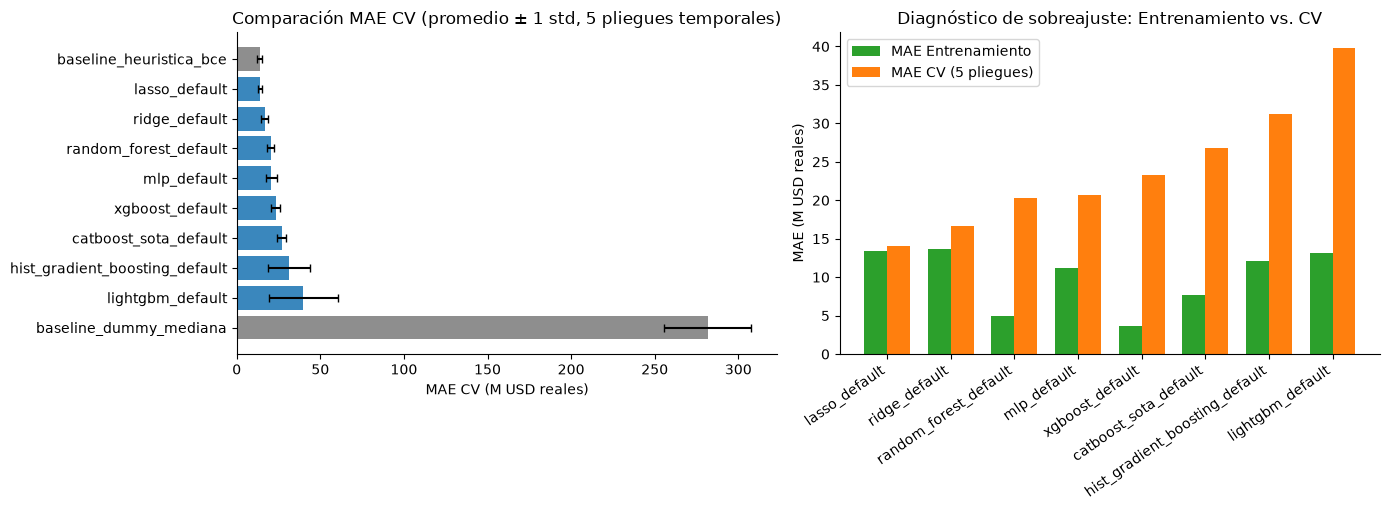

In [6]:
# Diagnóstico visual de desempeño CV y brecha de sobreajuste
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

plot_df = df_res.sort_values("mae_cv_promedio", ascending=False)
colores = ["#7f7f7f" if f == "baseline" else "#1f77b4" for f in plot_df["fase"]]
axes[0].barh(
    plot_df["nombre"],
    plot_df["mae_cv_promedio"],
    xerr=plot_df["mae_cv_std"],
    color=colores,
    alpha=0.88,
    capsize=3,
)
axes[0].set_title("Comparación MAE CV (promedio ± 1 std, 5 pliegues temporales)")
axes[0].set_xlabel("MAE CV (M USD reales)")

cand_df = df_res[df_res["fase"] == "candidato"].sort_values("mae_cv_promedio", ascending=True)
x_pos = np.arange(len(cand_df))
w = 0.36
axes[1].bar(x_pos - w/2, cand_df["mae_entrenamiento"], width=w, label="MAE Entrenamiento", color="#2ca02c")
axes[1].bar(x_pos + w/2, cand_df["mae_cv_promedio"], width=w, label="MAE CV (5 pliegues)", color="#ff7f0e")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(cand_df["nombre"], rotation=35, ha="right")
axes[1].set_ylabel("MAE (M USD reales)")
axes[1].set_title("Diagnóstico de sobreajuste: Entrenamiento vs. CV")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "03_comparacion_candidatos.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Evaluación formal de un LLM mediante prompting (análisis de viabilidad y costo)

Siguiendo la pauta del curso (`semana-10-sesion-02`), se construye el prompt *few-shot* real sobre **30 ejemplos del conjunto de entrenamiento** y **20 observaciones de validación del último pliegue temporal** para cuantificar tokens, costo y analizar por qué el *prompting* autorregresivo de un LLM no es adecuado para *nowcasting* macroeconómico mensual multi-rama frente a modelos tabulares entrenados en Python.

In [7]:
tr_f5, val_f5 = cv_temporal[-1]
ejemplos_llm = X_ent.iloc[tr_f5].sample(30, random_state=SEMILLA)
y_ejemplos_llm = y_ent.iloc[tr_f5].loc[ejemplos_llm.index]
muestra_llm = X_ent.iloc[val_f5].sample(20, random_state=SEMILLA)
y_muestra_llm = y_ent.iloc[val_f5].loc[muestra_llm.index]

cols_legibles = [
    "CODIGO_INDUSTRIA",
    "SECTOR_MACRO",
    "ventas_temprano_ipc_real",
    "RATIO_REPRESENTATIVIDAD_HIST_12M",
    "proyeccion_cobertura_12m",
    "NUM_DECLARANTES",
    "INDICE_PRECIO_REAL",
]

ej_csv = ejemplos_llm[cols_legibles].copy()
ej_csv["target_real_musd"] = y_ejemplos_llm.round(2).values
val_csv = muestra_llm[cols_legibles].copy()

prompt_llm = (
    "Eres un economista del BCE estimando ventas definitivas mensuales (en millones de USD reales) "
    "a partir del corte temprano del día 15. A continuación hay 30 observaciones históricas con su valor "
    "definitivo real y 20 observaciones por predecir. Responde únicamente con 20 números flotantes.\n\n"
    "Histórico:\n" + ej_csv.round(3).to_csv(index=False)
    + "\nPor predecir:\n" + val_csv.round(3).to_csv(index=False)
)

ruta_prompt = ROOT / "scratch" / "prompt_llm_nowcasting.txt"
ruta_prompt.parent.mkdir(exist_ok=True)
ruta_prompt.write_text(prompt_llm, encoding="utf-8")

n_chars = len(prompt_llm)
tokens_aprox = n_chars / 4.0
precio_1m_tokens = 2.50  # tarifa referencial API frontera (USD / 1M tokens de entrada)
costo_10000 = (10000 / 20) * (tokens_aprox / 1e6) * precio_1m_tokens

# Desempeño de la heurística BCE y de los 2 mejores candidatos en esas mismas 20 filas
pipe_bce = Pipeline([("m", HeuristicaBCE())]).fit(X_ent.iloc[tr_f5], y_ent.iloc[tr_f5])
mae_20_bce = calcular_metricas(y_muestra_llm, pipe_bce.predict(muestra_llm))["mae"]

top1_name = df_res[df_res["fase"] == "candidato"].iloc[0]["nombre"]
top1_cls = dict((n, m) for n, m, _ in candidatos)[top1_name]
pipe_top1 = Pipeline([("p", construir_preparacion()), ("m", clone(top1_cls))]).fit(X_ent.iloc[tr_f5], y_ent.iloc[tr_f5])
t_inf0 = time.perf_counter()
pred_20_top1 = np.clip(pipe_top1.predict(muestra_llm), 0.0, None)
ms_20_top1 = (time.perf_counter() - t_inf0) * 1000
mae_20_top1 = calcular_metricas(y_muestra_llm, pred_20_top1)["mae"]

print(f"Prompt generado en {ruta_prompt.name}: {n_chars} caracteres (~{int(tokens_aprox)} tokens por lote de 20 filas)")
print(f"Costo estimado de inferencia LLM para 10,000 predicciones: USD {costo_10000:.2f} (sin contar tokens de salida ni APIs privadas)")
print(f"En las mismas 20 filas -> Heurística BCE MAE={mae_20_bce:.3f} M | {top1_name} MAE={mae_20_top1:.3f} M ({ms_20_top1:.2f} ms)")
print("Conclusión técnica sobre LLM Prompting:")
print("  1. Cobertura de panel insuficiente: 30 ejemplos en contexto cubren <1 observación por cada una de las 46 ramas CIIU.")
print("  2. Falta de determinismo y calibración numérica: la generación autorregresiva de tokens no garantiza reproducibilidad exacta ni minimización de MAE/WAPE.")
print("  3. Gobernanza y confidencialidad tributaria: enviar datos fiscales F104 a APIs externas añade latencia, costo recurrente y riesgo de privacidad frente a un pipeline local auditable.")

Prompt generado en prompt_llm_nowcasting.txt: 3930 caracteres (~982 tokens por lote de 20 filas)
Costo estimado de inferencia LLM para 10,000 predicciones: USD 1.23 (sin contar tokens de salida ni APIs privadas)
En las mismas 20 filas -> Heurística BCE MAE=20.832 M | lasso_default MAE=19.655 M (3.72 ms)
Conclusión técnica sobre LLM Prompting:
  1. Cobertura de panel insuficiente: 30 ejemplos en contexto cubren <1 observación por cada una de las 46 ramas CIIU.
  2. Falta de determinismo y calibración numérica: la generación autorregresiva de tokens no garantiza reproducibilidad exacta ni minimización de MAE/WAPE.
  3. Gobernanza y confidencialidad tributaria: enviar datos fiscales F104 a APIs externas añade latencia, costo recurrente y riesgo de privacidad frente a un pipeline local auditable.


## 6. Hallazgos de comparación justa (Baselines vs. Candidatos por defecto)

1. **Superación de la línea base ingenua:** los 8 modelos candidatos superan holgadamente a `baseline_dummy_mediana` (`MAE CV = 281.68 ± 26.09 M USD`, `WAPE = 76.97%`), reduciendo el error entre 7× y 20×.
2. **Dificultad de superar la heurística de dominio sin ajuste (`baseline_heuristica_bce`):** ningún candidato con hiperparámetros por defecto supera la regla de negocio del PSet #1 en `MAE CV` (`13.80 ± 1.48 M`), aunque **`lasso_default` (`14.09 ± 1.16 M`) ya la supera en métrica de negocio asimétrica (`17.15` vs. `17.42 M USD`)** y tiene menor desviación entre pliegues (`1.16` vs. `1.48 M`).
3. **Diagnóstico de sobreajuste y extrapolación en árboles:** `random_forest_default`, `xgboost_default`, `catboost_sota_default`, `hist_gradient_boosting_default` y `lightgbm_default` exhiben brechas severas de sobreajuste (`+15.3` a `+26.7 M USD` entre entrenamiento y CV). Al predecir promedios constantes por hoja, los árboles no extrapolan linealmente cuando ramas de gran escala (p. ej. Comercio) superan en pliegues recientes los máximos observados en los primeros años de entrenamiento (`TimeSeriesSplit`).
4. **Selección para Fine-Tuning:** los **3 mejores candidatos** en `MAE CV` que pasan a `04_tuning.ipynb` son `lasso_default`, `ridge_default` y `random_forest_default`.